# M5.1 · 事件驱动回测引擎

> 向量化回测快但无法表达订单生命周期、部分成交、涨跌停拒单等真实机制。事件驱动引擎把回测组织成一条**事件流**：行情 → 信号 → 订单 → 成交，逐笔更新现金与持仓台账，更贴近实盘。

## 一、架构与事件类型

1. **事件队列**：MARKET（行情）、SIGNAL（信号）、ORDER（订单）、FILL（成交）；
2. **订单 / 成交**：Order（市价/限价、方向、数量、状态）、Fill（成交价、量、费用）；
3. **Portfolio 台账**：现金、持仓、市值、净值，成交逐笔更新；
4. **撮合器**：市价单按当前 bar 开盘价成交，限价单判断价格是否触及；
5. **事件循环**：每根 bar 推送 MARKET，策略 `on_bar` 产生 ORDER，撮合后 FILL 更新台账，记录净值。

## 二、数据准备与策略

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from bt_lab2 import event_engine as ee
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
fields = ['$open', '$high', '$low', '$close', '$volume']
raw = D.features(codes, fields, start_time='2018-01-01', freq='day')
tables = {f: raw[f].unstack('instrument') for f in fields}
sel = codes[:5]
bars = {}
for c in sel:
    bars[c] = pd.DataFrame({'open': tables['$open'][c], 'high': tables['$high'][c],
                            'low': tables['$low'][c], 'close': tables['$close'][c],
                            'volume': tables['$volume'][c]}).dropna().iloc[-250:]

class BuyHold:
    def __init__(self): self.done = False
    def on_bar(self, date, bar_dict, pf):
        orders = []
        if not self.done:
            per = pf.init_cash / len(bar_dict)
            for c, b in bar_dict.items():
                qty = int(per / b['open'] / 100) * 100
                if qty > 0:
                    orders.append(ee.Order(c, qty, 'BUY', 'MARKET'))
            self.done = True
        return orders

eng = ee.EventDrivenBacktest(bars, BuyHold(), init_cash=1e7)
nav = eng.run()
print('成交笔数=%d 末日净值=%.0f 累计收益=%.4f'
      % (len(eng.fills), nav['equity'].iloc[-1], nav['equity'].iloc[-1]/1e7-1))
print('事件队列示例: MARKET/ORDER/FILL, 共 %d 个交易日' % len(nav))

[23196:MainThread](2026-11-05 14:55:45,180) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[23196:MainThread](2026-11-05 14:55:47,000) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[23196:MainThread](2026-11-05 14:55:47,002) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


成交笔数=5 末日净值=7929797 累计收益=-0.2070
事件队列示例: MARKET/ORDER/FILL, 共 250 个交易日


## 三、可视化

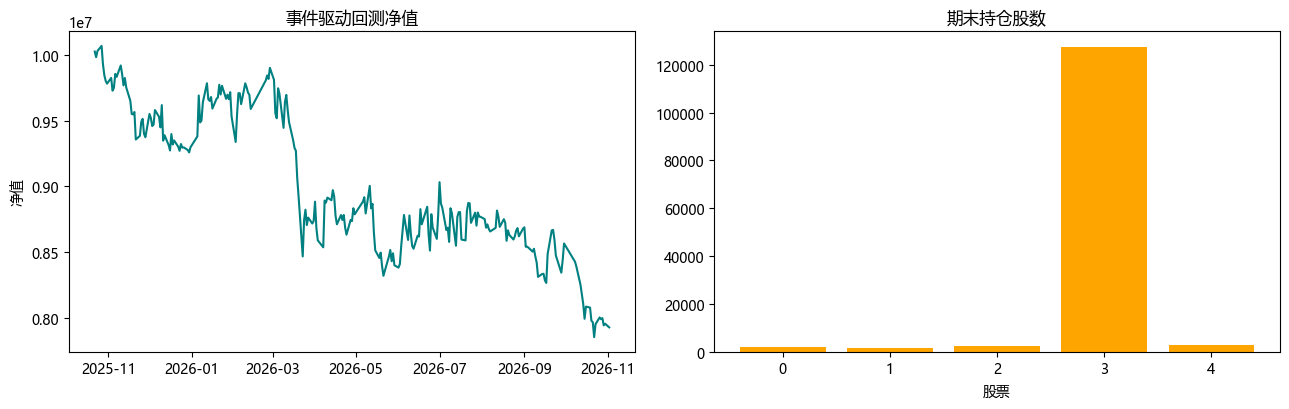

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(nav.index, nav['equity'].values, color='teal')
ax[0].set_title('事件驱动回测净值'); ax[0].set_ylabel('净值')
ax[1].bar(np.arange(5), [eng.portfolio.positions.get(c, 0) for c in sel], color='orange')
ax[1].set_title('期末持仓股数'); ax[1].set_xlabel('股票')
plt.tight_layout(); plt.show()

## 四、面试要点

- **事件驱动 vs 向量化回测？** 向量化用矩阵一次算完，快但无法表达订单状态/部分成交/拒单；事件驱动逐事件撮合，精度高、可复用实盘代码，代价是慢。
- **事件处理顺序为何重要？** 必须保证「先收行情、再决策、后撮合、最后更新台账」，错乱会引入未来函数或重复记账。
- **如何防止未来函数？** 信号在 t 日收盘生成、t+1 开盘撮合成交，决策只使用当前及之前信息。
- **台账要核对什么？** 现金 + 持仓市值 = 净值，买卖成交后现金与持仓必须同步更新，日终对账。

## 五、练习

1. 把 BasicMatcher 改为按收盘价成交，比较净值差异。
2. 增加一个限价单策略，观察未成交订单如何处理。
3. 加入佣金/印花税，重新计算净值并核对现金。
4. 思考：事件引擎如何支持多资产、多策略并发？